# Modelagem — recorrências diárias de alarmes

Este notebook treina e compara Random Forest e XGBoost para prever o número diário de recorrências com IAT positivo inferior a 30 minutos. Cada algoritmo é avaliado com os conjuntos simples e completo de features.

A seleção de hiperparâmetros usa janelas expansivas dentro do período de desenvolvimento. Os últimos 365 dias de calendário são mantidos isolados até a avaliação final.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
import xgboost

from src.modeling import (
    TARGET_COL,
    build_expanding_validation,
    build_model_comparison,
    evaluate_lag1_baseline,
    load_feature_dataset,
    plot_feature_importance,
    plot_model_comparison,
    plot_predictions,
    plot_residuals,
    plot_validation_windows,
    run_experiment,
    save_baseline_artifacts,
    save_experiment_artifacts,
    split_final_holdout,
    validate_aligned_datasets,
)

SIMPLE_FEATURES_PATH = Path('src/feats/features_simple.csv')
COMPLETE_FEATURES_PATH = Path('src/feats/features_final.csv')
OUTPUT_DIR = Path('results/modeling')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TEST_DAYS = 365
INITIAL_TRAIN_DAYS = 730
VALIDATION_DAYS = 180
STEP_DAYS = 180
RANDOM_STATE = 42
N_JOBS = -1

print(f'scikit-learn: {sklearn.__version__}')
print(f'XGBoost: {xgboost.__version__}')

scikit-learn: 1.9.0
XGBoost: 3.2.0


## 1. Carregamento dos datasets

Os dois arquivos devem conter as mesmas datas e o mesmo alvo. A única diferença entre eles é o conjunto de preditores.

In [2]:
simple_dataset = load_feature_dataset(SIMPLE_FEATURES_PATH)
complete_dataset = load_feature_dataset(COMPLETE_FEATURES_PATH)
validate_aligned_datasets(simple_dataset, complete_dataset)

dataset_summary = pd.DataFrame([
    {
        'Dataset': 'simple',
        'Rows': len(simple_dataset),
        'Predictors': simple_dataset.shape[1] - 3,
        'Start': simple_dataset['Date'].min(),
        'End': simple_dataset['Date'].max(),
    },
    {
        'Dataset': 'complete',
        'Rows': len(complete_dataset),
        'Predictors': complete_dataset.shape[1] - 3,
        'Start': complete_dataset['Date'].min(),
        'End': complete_dataset['Date'].max(),
    },
])
display(dataset_summary)
display(simple_dataset[[
    'Date', TARGET_COL, 'AlarmVolume_lag1d', 'GapFlag_lag1d'
]].head())

[LOG] Loaded src\feats\features_simple.csv: 1,499 rows x 16 predictors
[LOG] Loaded src\feats\features_final.csv: 1,499 rows x 36 predictors


,Dataset,Rows,Predictors,Start,End
0,simple,1499,16,2020-02-08 00:00:00-03:00,2025-05-16 00:00:00-03:00
1,complete,1499,36,2020-02-08 00:00:00-03:00,2025-05-16 00:00:00-03:00


,Date,recurrences_lt_30m,AlarmVolume_lag1d,GapFlag_lag1d
0,2020-02-08 00:00:00-03:00,46,87.0,0.0
1,2020-02-09 00:00:00-03:00,1,136.0,0.0
2,2020-02-10 00:00:00-03:00,5,22.0,0.0
3,2020-02-11 00:00:00-03:00,70,58.0,0.0
4,2020-02-12 00:00:00-03:00,13,119.0,0.0


## 2. Teste final isolado

Os últimos 365 dias de calendário não participam da busca de hiperparâmetros.

In [3]:
simple_development, simple_test, holdout_summary = split_final_holdout(
    simple_dataset,
    test_days=TEST_DAYS,
)
complete_development, complete_test, _ = split_final_holdout(
    complete_dataset,
    test_days=TEST_DAYS,
)
validate_aligned_datasets(simple_development, complete_development)
validate_aligned_datasets(simple_test, complete_test)
display(holdout_summary)

[LOG] Final test isolated: 2024-05-17 to 2025-05-16 (359 available rows)
[LOG] Final test isolated: 2024-05-17 to 2025-05-16 (359 available rows)


,Development_start,Development_end,Development_rows,Test_start,Test_end,Test_rows,Test_calendar_days
0,2020-02-08 00:00:00-03:00,2024-05-16 00:00:00-03:00,1140,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00,359,365


## 3. Validação temporal por janela expansiva

Cada fold mantém dois anos iniciais ou mais no treino e avalia os 180 dias seguintes. O treino cresce a cada iteração, enquanto o teste final permanece fora desses folds.

[LOG] Expanding-window validation created: 5 fold(s)


,Fold,Train_start,Train_end,Validation_start,Validation_end,Train_rows,Validation_rows
0,1,2020-02-08 00:00:00-03:00,2022-02-06 00:00:00-03:00,2022-02-07 00:00:00-03:00,2022-07-27 00:00:00-03:00,585,138
1,2,2020-02-08 00:00:00-03:00,2022-07-27 00:00:00-03:00,2022-10-06 00:00:00-03:00,2023-02-01 00:00:00-03:00,723,107
2,3,2020-02-08 00:00:00-03:00,2023-02-01 00:00:00-03:00,2023-02-02 00:00:00-03:00,2023-07-31 00:00:00-03:00,830,130
3,4,2020-02-08 00:00:00-03:00,2023-07-31 00:00:00-03:00,2023-08-01 00:00:00-03:00,2024-01-27 00:00:00-03:00,960,79
4,5,2020-02-08 00:00:00-03:00,2024-01-27 00:00:00-03:00,2024-01-28 00:00:00-03:00,2024-05-16 00:00:00-03:00,1039,101


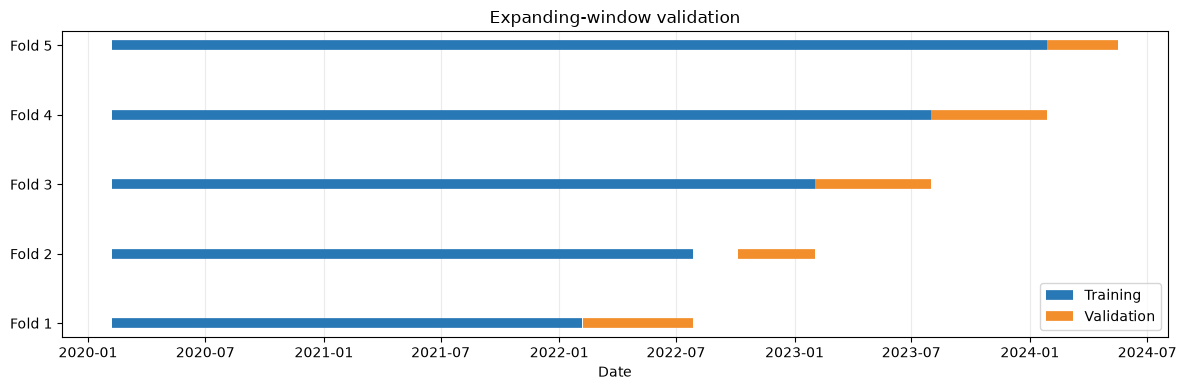

In [4]:
validation_splits, validation_summary = build_expanding_validation(
    simple_development,
    initial_train_days=INITIAL_TRAIN_DAYS,
    validation_days=VALIDATION_DAYS,
    step_days=STEP_DAYS,
)
display(validation_summary)
plot_validation_windows(validation_summary)
plt.show()

## 4. Baseline de persistência diária

O baseline prevê para cada data o alvo observado no dia anterior. Quando esse alvo anterior está indisponível, a data não entra na métrica do baseline.

In [5]:
baseline_result = evaluate_lag1_baseline(simple_dataset, simple_test)
display(pd.DataFrame([baseline_result['metrics']]))

[LOG] Lag-1 baseline: MAE=11.462, coverage=99.4% (357/359 rows)


,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted,Model,Dataset,Coverage,Test_start,Test_end
0,357,11.462185,20.42531,-0.742894,62.74697,10.854342,10.876751,lag1_baseline,target_only,0.994429,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00


## 5. Random Forest — modelo simples

A busca compacta seleciona a configuração com menor MAE médio nos folds expansivos.

In [6]:
rf_simple = run_experiment(
    model_name='random_forest',
    dataset_name='simple',
    development_dataset=simple_development,
    test_dataset=simple_test,
    splits=validation_splits,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)
display(rf_simple['search_summary'])
display(pd.DataFrame([rf_simple['test_metrics']]))

[LOG] random_forest: candidate 1/6 across 5 fold(s)
[LOG] random_forest: candidate 2/6 across 5 fold(s)
[LOG] random_forest: candidate 3/6 across 5 fold(s)
[LOG] random_forest: candidate 4/6 across 5 fold(s)
[LOG] random_forest: candidate 5/6 across 5 fold(s)
[LOG] random_forest: candidate 6/6 across 5 fold(s)
[LOG] random_forest: selected candidate 6 (CV MAE=17.000)
[LOG] random_forest/simple: test MAE=10.994, RMSE=16.746, R2=-0.175


,Candidate,Parameters,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_PoissonDeviance_mean,Folds
0,6,"{""max_depth"": 20, ""max_features"": 0.7, ""min_sa...",17.000460,4.905436,27.924724,12.814195,-5.185516,27.488358,5
1,3,"{""max_depth"": 12, ""max_features"": 1.0, ""min_sa...",17.363886,5.761143,29.692100,13.079829,-6.882396,28.486263,5
2,5,"{""max_depth"": null, ""max_features"": 0.7, ""min_...",18.193635,5.640482,30.528002,13.102736,-6.643291,29.732392,5
3,4,"{""max_depth"": 20, ""max_features"": ""sqrt"", ""min...",18.398241,5.169064,29.538378,12.584688,-6.337835,30.389506,5
4,2,"{""max_depth"": 12, ""max_features"": 1.0, ""min_sa...",18.610760,6.309672,33.117918,14.744705,-5.973621,30.371958,5
5,1,"{""max_depth"": null, ""max_features"": 1.0, ""min_...",19.290304,6.319646,33.503395,14.613585,-6.758340,31.241200,5


,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted,Model,Dataset,Test_start,Test_end
0,359,10.994128,16.745544,-0.175097,14.639403,10.796657,13.852218,random_forest,simple,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00


## 6. Random Forest — modelo completo

In [7]:
rf_complete = run_experiment(
    model_name='random_forest',
    dataset_name='complete',
    development_dataset=complete_development,
    test_dataset=complete_test,
    splits=validation_splits,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)
display(rf_complete['search_summary'])
display(pd.DataFrame([rf_complete['test_metrics']]))

[LOG] random_forest: candidate 1/6 across 5 fold(s)
[LOG] random_forest: candidate 2/6 across 5 fold(s)
[LOG] random_forest: candidate 3/6 across 5 fold(s)
[LOG] random_forest: candidate 4/6 across 5 fold(s)
[LOG] random_forest: candidate 5/6 across 5 fold(s)
[LOG] random_forest: candidate 6/6 across 5 fold(s)
[LOG] random_forest: selected candidate 6 (CV MAE=16.707)
[LOG] random_forest/complete: test MAE=11.155, RMSE=16.337, R2=-0.118


,Candidate,Parameters,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_PoissonDeviance_mean,Folds
0,6,"{""max_depth"": 20, ""max_features"": 0.7, ""min_sa...",16.706899,5.402609,27.421602,13.446898,-3.967248,26.826809,5
1,3,"{""max_depth"": 12, ""max_features"": 1.0, ""min_sa...",17.342745,6.070458,29.598437,13.258553,-6.087968,27.461360,5
2,4,"{""max_depth"": 20, ""max_features"": ""sqrt"", ""min...",17.588521,5.841350,27.806631,13.742567,-3.837101,28.230454,5
3,5,"{""max_depth"": null, ""max_features"": 0.7, ""min_...",18.011475,6.379509,29.911879,13.778627,-5.135223,28.509989,5
4,2,"{""max_depth"": 12, ""max_features"": 1.0, ""min_sa...",18.202835,7.633374,30.942198,16.852786,-3.436308,28.557834,5
5,1,"{""max_depth"": null, ""max_features"": 1.0, ""min_...",19.163572,7.854447,31.740124,17.123175,-3.611027,29.947991,5


,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted,Model,Dataset,Test_start,Test_end
0,359,11.155468,16.337231,-0.118489,14.460354,10.796657,14.392281,random_forest,complete,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00


## 7. XGBoost — modelo simples

O XGBoost usa objetivo Poisson, apropriado para um alvo de contagem não negativo.

In [8]:
xgb_simple = run_experiment(
    model_name='xgboost',
    dataset_name='simple',
    development_dataset=simple_development,
    test_dataset=simple_test,
    splits=validation_splits,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)
display(xgb_simple['search_summary'])
display(pd.DataFrame([xgb_simple['test_metrics']]))

[LOG] xgboost: candidate 1/6 across 5 fold(s)
[LOG] xgboost: candidate 2/6 across 5 fold(s)
[LOG] xgboost: candidate 3/6 across 5 fold(s)
[LOG] xgboost: candidate 4/6 across 5 fold(s)
[LOG] xgboost: candidate 5/6 across 5 fold(s)
[LOG] xgboost: candidate 6/6 across 5 fold(s)
[LOG] xgboost: selected candidate 6 (CV MAE=13.943)
[LOG] xgboost/simple: test MAE=9.267, RMSE=15.302, R2=0.019


,Candidate,Parameters,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_PoissonDeviance_mean,Folds
0,6,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",13.942640,4.849314,26.848205,16.009660,-1.303469,28.001636,5
1,5,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",13.983992,4.769521,27.090605,15.763744,-1.488787,29.015470,5
2,4,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",14.835045,5.362711,29.369029,17.716012,-1.895080,29.492192,5
3,2,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",15.222393,5.806754,28.487713,17.305325,-1.707770,27.343002,5
4,3,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",15.247470,5.263000,29.093430,17.196850,-1.967207,28.673225,5
5,1,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",15.678923,5.625160,28.128356,16.252603,-1.981962,27.195537,5


,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted,Model,Dataset,Test_start,Test_end
0,359,9.267219,15.302343,0.018725,13.147575,10.796657,10.82812,xgboost,simple,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00


## 8. XGBoost — modelo completo

In [9]:
xgb_complete = run_experiment(
    model_name='xgboost',
    dataset_name='complete',
    development_dataset=complete_development,
    test_dataset=complete_test,
    splits=validation_splits,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)
display(xgb_complete['search_summary'])
display(pd.DataFrame([xgb_complete['test_metrics']]))

[LOG] xgboost: candidate 1/6 across 5 fold(s)
[LOG] xgboost: candidate 2/6 across 5 fold(s)
[LOG] xgboost: candidate 3/6 across 5 fold(s)
[LOG] xgboost: candidate 4/6 across 5 fold(s)
[LOG] xgboost: candidate 5/6 across 5 fold(s)
[LOG] xgboost: candidate 6/6 across 5 fold(s)
[LOG] xgboost: selected candidate 5 (CV MAE=13.821)
[LOG] xgboost/complete: test MAE=8.817, RMSE=15.048, R2=0.051


,Candidate,Parameters,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_PoissonDeviance_mean,Folds
0,5,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",13.820996,4.683482,26.411810,15.794624,-1.267774,29.098526,5
1,6,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",13.885185,5.005186,27.014147,16.865219,-1.248812,28.328904,5
2,4,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",14.006189,4.460027,25.897105,15.351511,-1.312522,28.656983,5
3,3,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",14.401724,4.623320,26.195244,15.298203,-1.552513,27.445738,5
4,2,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",14.519714,5.274461,26.662892,16.219871,-1.523497,26.855622,5
5,1,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",15.247862,5.032836,26.774329,15.559192,-1.882771,26.632609,5


,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted,Model,Dataset,Test_start,Test_end
0,359,8.816675,15.047539,0.051132,12.762339,10.796657,10.035645,xgboost,complete,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00


## 9. Comparação no teste final

MAE é a métrica principal. RMSE evidencia erros grandes, R² mede o ganho em relação à média e o desvio de Poisson avalia a adequação das previsões de contagem. MAPE não é usado porque o alvo contém zeros.

,Model,Dataset,Rows,Coverage,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted
0,xgboost,complete,359,1.000000,8.816675,15.047539,0.051132,12.762339,10.796657,10.035645
1,xgboost,simple,359,1.000000,9.267219,15.302343,0.018725,13.147575,10.796657,10.828120
2,random_forest,simple,359,1.000000,10.994128,16.745544,-0.175097,14.639403,10.796657,13.852218
3,random_forest,complete,359,1.000000,11.155468,16.337231,-0.118489,14.460354,10.796657,14.392281
4,lag1_baseline,target_only,357,0.994429,11.462185,20.425310,-0.742894,62.746970,10.854342,10.876751


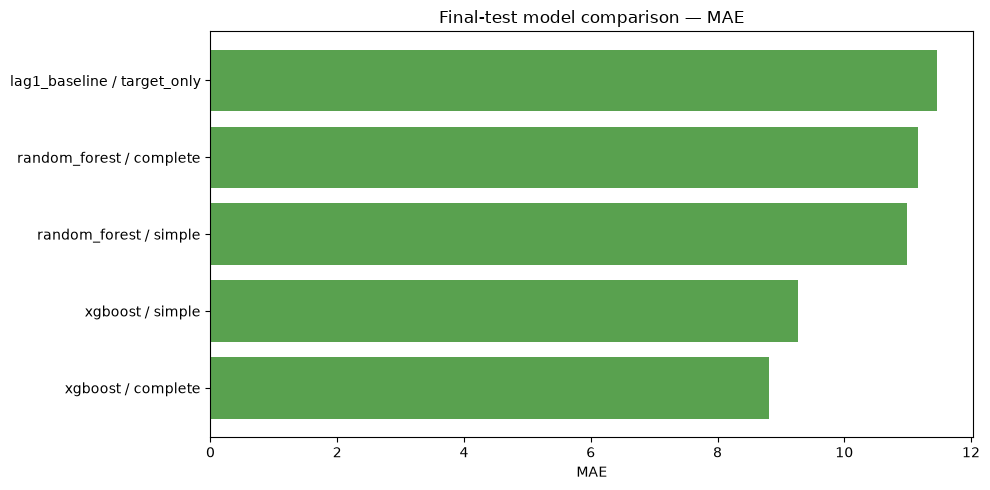

In [10]:
experiments = [rf_simple, rf_complete, xgb_simple, xgb_complete]
comparison = build_model_comparison(experiments, baseline_result)
display(comparison[[
    'Model', 'Dataset', 'Rows', 'Coverage', 'MAE', 'RMSE', 'R2',
    'PoissonDeviance', 'MeanActual', 'MeanPredicted',
]])
plot_model_comparison(comparison, metric='MAE')
plt.show()

## 10. Diagnósticos dos quatro experimentos

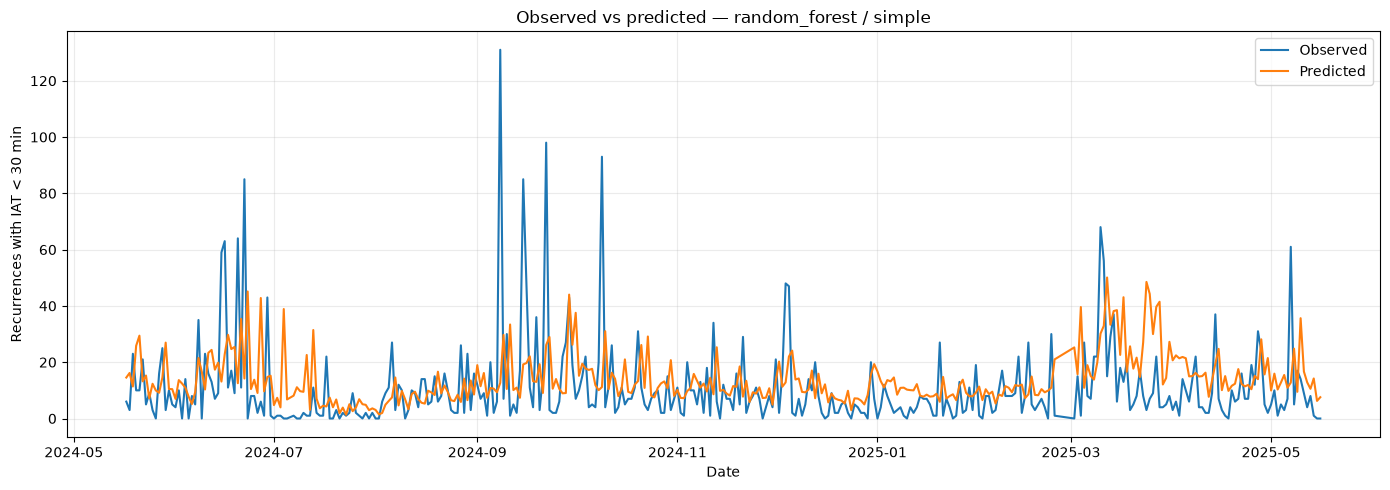

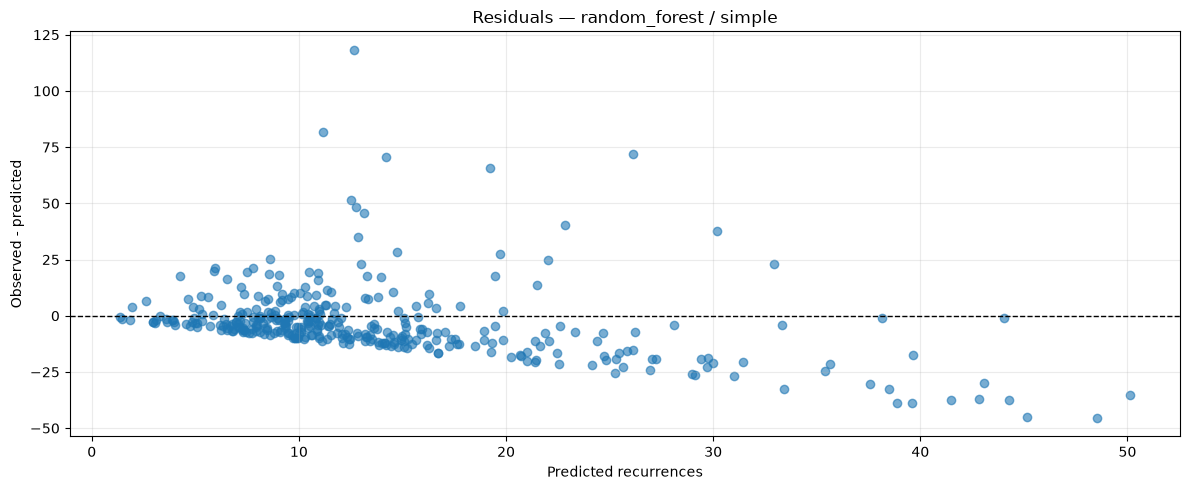

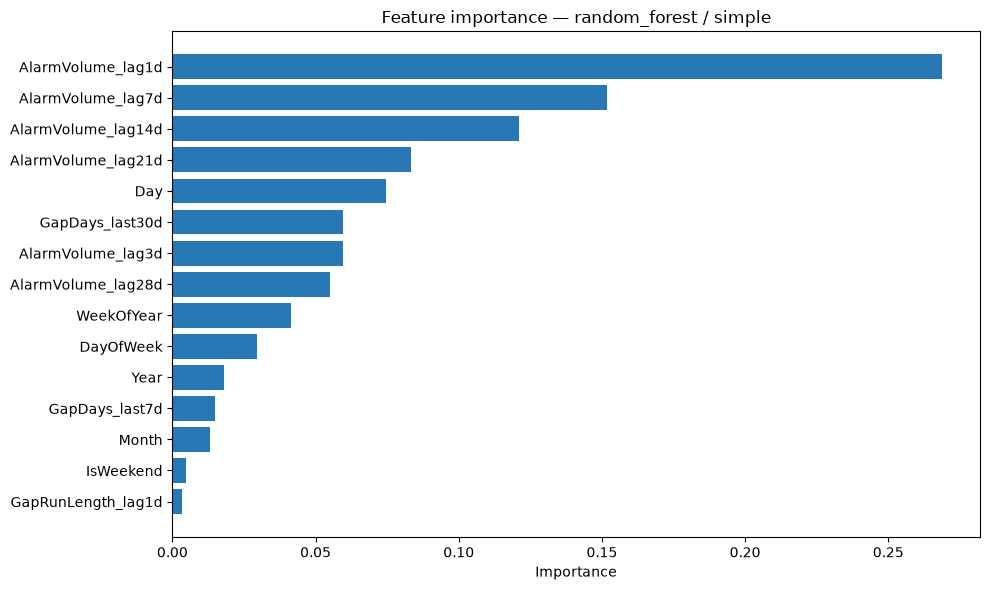

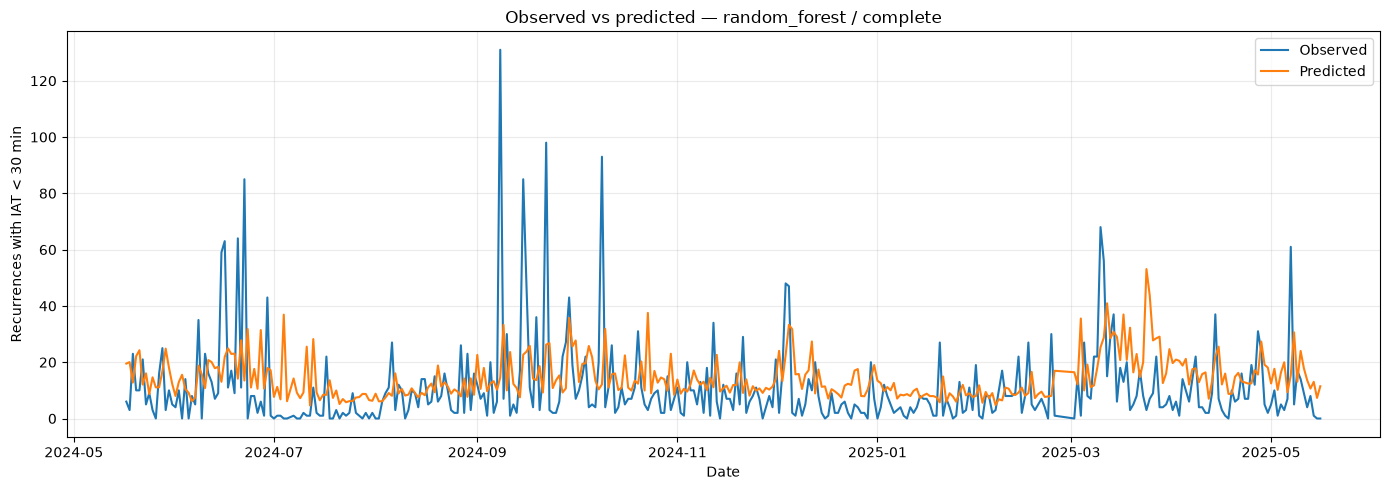

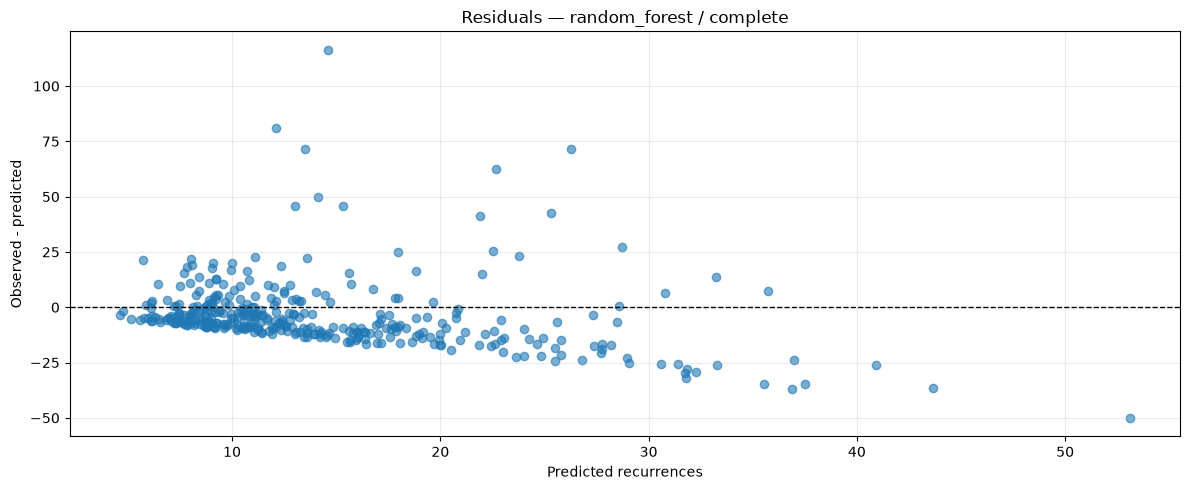

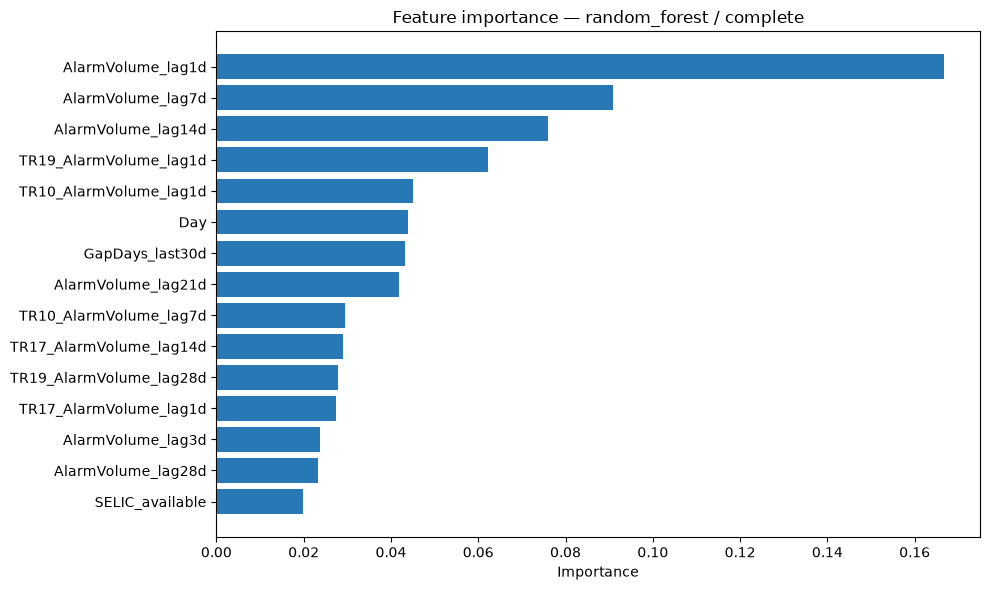

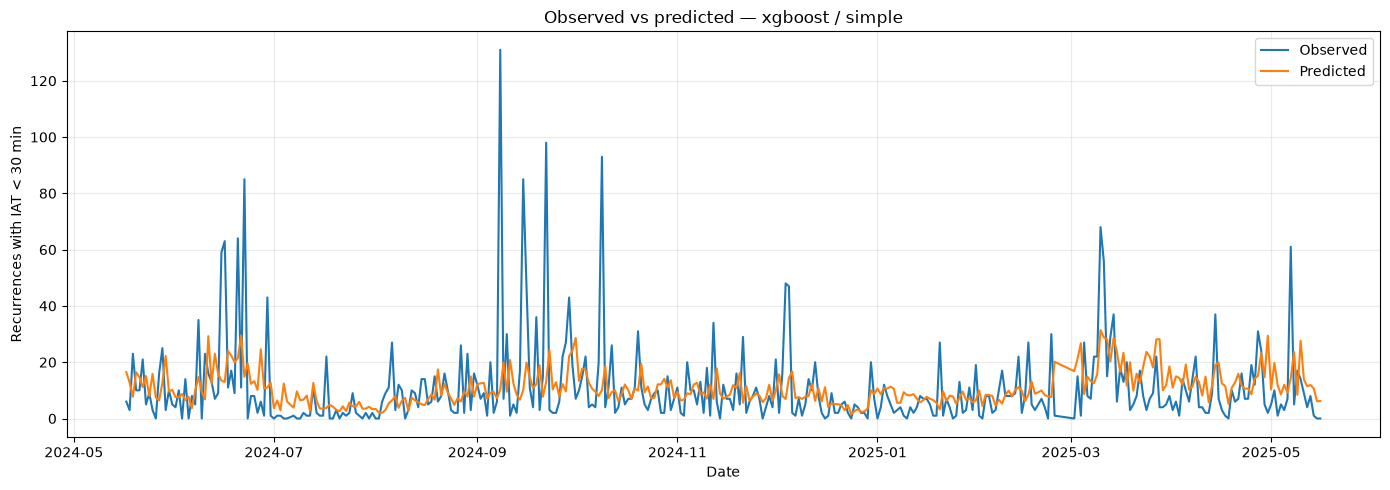

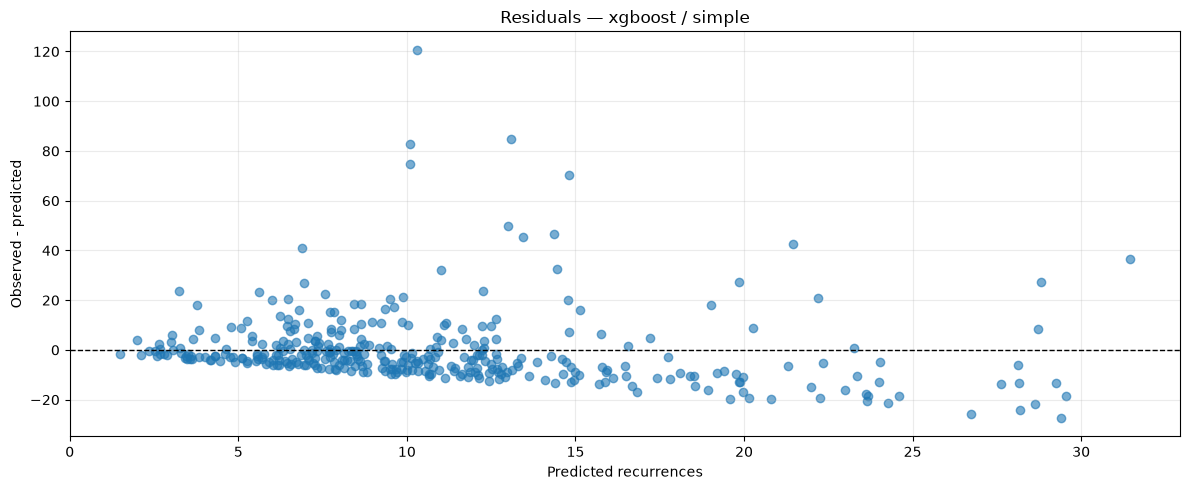

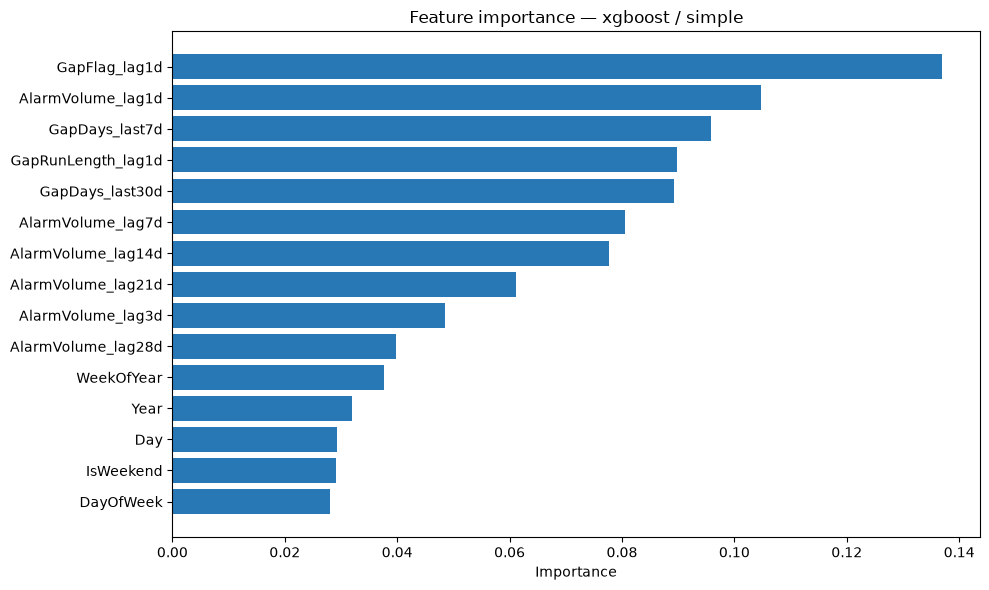

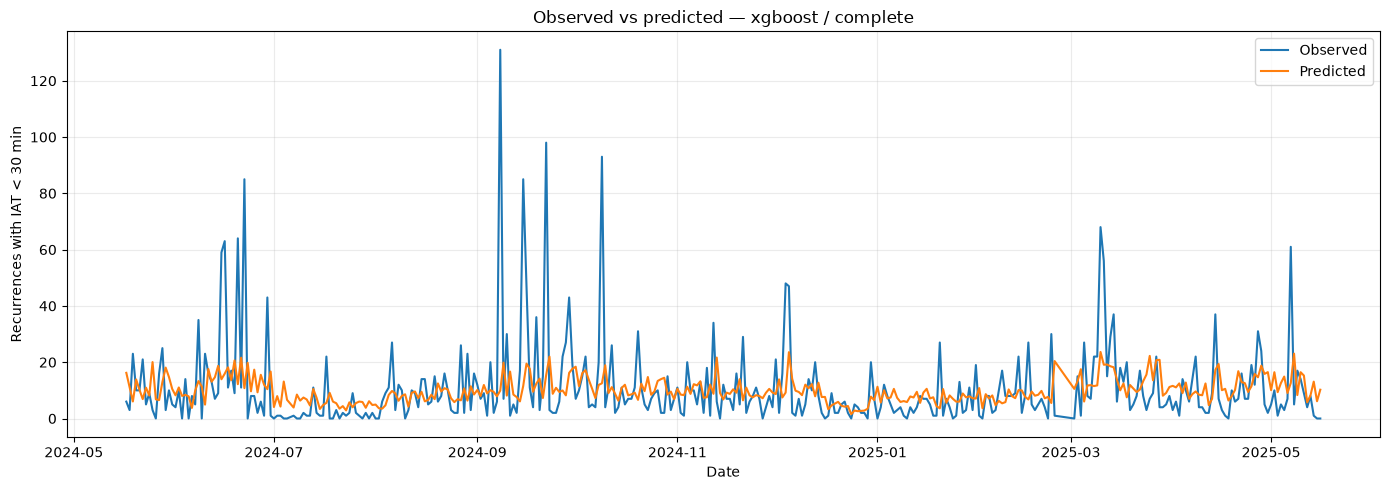

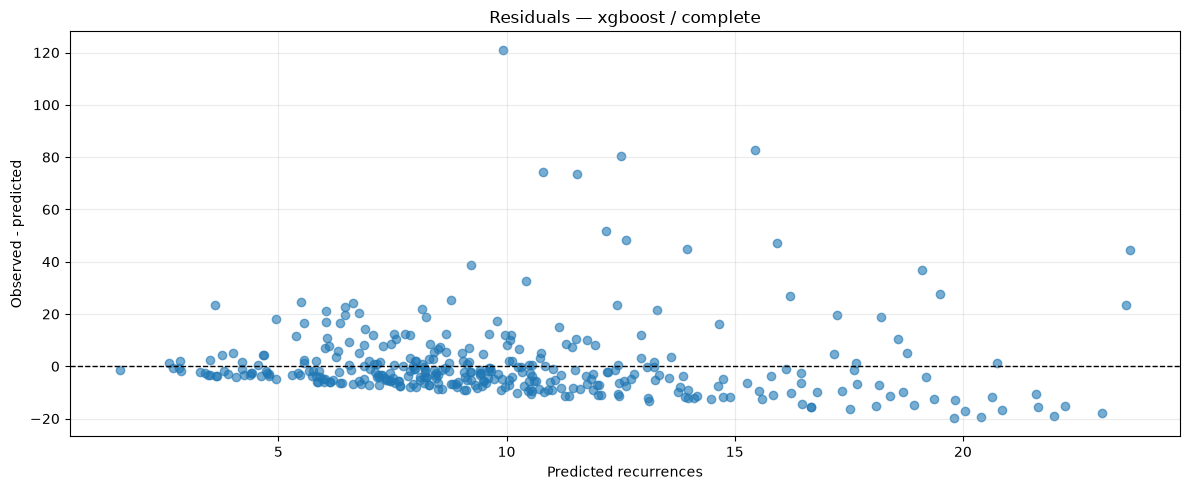

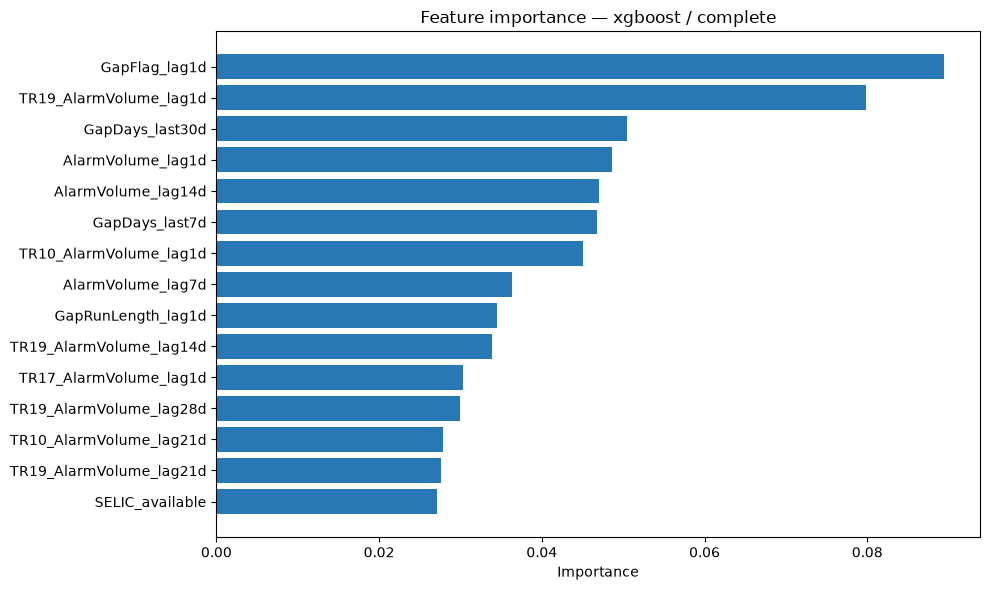

In [11]:
for experiment in experiments:
    label = f"{experiment['model_name']} / {experiment['dataset_name']}"

    figure, _ = plot_predictions(
        experiment['predictions'],
        title=f'Observed vs predicted — {label}',
    )
    figure.savefig(
        OUTPUT_DIR / f"{experiment['model_name']}_{experiment['dataset_name']}_predictions.png",
        dpi=150,
        bbox_inches='tight',
    )
    plt.show()

    figure, _ = plot_residuals(
        experiment['predictions'],
        title=f'Residuals — {label}',
    )
    figure.savefig(
        OUTPUT_DIR / f"{experiment['model_name']}_{experiment['dataset_name']}_residuals.png",
        dpi=150,
        bbox_inches='tight',
    )
    plt.show()

    figure, _ = plot_feature_importance(
        experiment['feature_importance'],
        title=f'Feature importance — {label}',
    )
    figure.savefig(
        OUTPUT_DIR / f"{experiment['model_name']}_{experiment['dataset_name']}_feature_importance.png",
        dpi=150,
        bbox_inches='tight',
    )
    plt.show()

## 11. Persistência dos resultados

São salvos o estimador ajustado, os hiperparâmetros, as métricas, as previsões do teste, a busca temporal e a importância das features.

In [16]:
artifact_paths = {}
for experiment in experiments:
    key = f"{experiment['model_name']}_{experiment['dataset_name']}"
    artifact_paths[key] = save_experiment_artifacts(experiment, OUTPUT_DIR)

artifact_paths['lag1_baseline'] = save_baseline_artifacts(
    baseline_result,
    OUTPUT_DIR,
)
comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
validation_summary.to_csv(OUTPUT_DIR / 'validation_windows.csv', index=False)
holdout_summary.to_csv(OUTPUT_DIR / 'final_holdout.csv', index=False)

best_result = comparison.loc[comparison['Model'].ne('lag1_baseline')].iloc[0]
print(
    f"Best final-test model by MAE: {best_result['Model']} / "
    f"{best_result['Dataset']} (MAE={best_result['MAE']:.3f})"
)
print(f'Artifacts saved to: project_workspace/results/modelling')

[LOG] Saved experiment artifacts with prefix results\modeling\random_forest_simple
[LOG] Saved experiment artifacts with prefix results\modeling\random_forest_complete
[LOG] Saved experiment artifacts with prefix results\modeling\xgboost_simple
[LOG] Saved experiment artifacts with prefix results\modeling\xgboost_complete
Best final-test model by MAE: xgboost / complete (MAE=8.817)
Artifacts saved to: project_workspace/results/modelling


## Saídas

O diretório `results/modeling/` reúne os quatro modelos treinados, resultados de validação, previsões do teste final, métricas, importâncias e figuras diagnósticas.